In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

In [5]:
import os

print("Current location:", os.getcwd())
print("Files here:", os.listdir())

Current location: C:\Users\USER\Desktop\AI JOB SIMULATION\NOTES.md
Files here: ['.ipynb_checkpoints', 'day2_eda.ipynb', 'ml_model.ipynb', 'notes.md']


In [7]:
os.chdir(r'C:\Users\USER\Desktop\AI JOB SIMULATION')

print("Current location:", os.getcwd())
print("Datasets folder exists:", os.path.exists('datasets'))

Current location: C:\Users\USER\Desktop\AI JOB SIMULATION
Datasets folder exists: True


In [8]:
with open('datasets/preprocessed_jobs.json', 'r', encoding='utf-8') as file:
    ml_jobs = json.load(file)

print("Total jobs:", len(ml_jobs))
print("First job title:", ml_jobs[0]['title'])

Total jobs: 2471
First job title: Software Engineer - Development


In [9]:
print("Available columns:")
print(ml_jobs[0].keys())

Available columns:
dict_keys(['id', 'title', 'company', 'location', 'description', 'seniority_level', 'employment_type', 'job_function', 'industry', 'url', 'posted_at', 'scraped_at', 'role_family_hint', 'domain_hint', 'experience_years_hint', 'remote_hint', 'lemmatized_description'])


In [10]:
ml_df = pd.DataFrame(ml_jobs)
X = ml_df[['title', 'lemmatized_description']]
y = ml_df['role_family_hint']
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

X shape: (2471, 2)
y shape: (2471,)

Target distribution:
role_family_hint
fullstack           310
data                240
backend             231
operations          194
product             187
marketing           181
hr                  166
frontend            162
finance             159
devops              139
sales               135
non-tech            128
customer_success     89
legal                76
mobile               74
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.2,random_state=42,stratify=y)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1976
Testing records: 495


In [12]:
X_train_text = (X_train['title'].fillna('') + ' ' +X_train['lemmatized_description'].fillna(''))
X_test_text = (X_test['title'].fillna('') + ' ' +X_test['lemmatized_description'].fillna(''))
print("Training text:", X_train_text.shape)
print("Testing text:", X_test_text.shape)

Training text: (1976,)
Testing text: (495,)


In [13]:
## vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=10000,ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (1976, 5509)
Testing matrix: (495, 5509)


In [15]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42)
lr_model.fit(X_train_tfidf, y_train)
print("Logistic Regression training completed")

Logistic Regression training completed


In [16]:
y_pred = lr_model.predict(X_test_tfidf)
print("Predictions completed!")
print("Total predictions:", len(y_pred))
print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions completed!
Total predictions: 495

First 10 predictions:
['data' 'hr' 'backend' 'non-tech' 'devops' 'frontend' 'product' 'product'
 'data' 'backend']


In [17]:
from sklearn.metrics import accuracy_score, classification_report
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 61.01 %

Classification Report:
                  precision    recall  f1-score   support

         backend       0.59      0.57      0.58        46
customer_success       0.56      0.56      0.56        18
            data       0.62      0.58      0.60        48
          devops       0.41      0.93      0.57        28
         finance       0.69      0.84      0.76        32
        frontend       0.55      0.84      0.67        32
       fullstack       0.67      0.16      0.26        62
              hr       0.72      0.88      0.79        33
           legal       0.69      0.60      0.64        15
       marketing       0.69      0.69      0.69        36
          mobile       0.57      0.53      0.55        15
        non-tech       0.27      0.12      0.16        26
      operations       0.76      0.72      0.74        39
         product       0.66      0.55      0.60        38
           sales       0.64      0.93      0.76        27

        accuracy      

<Figure size 1200x1000 with 0 Axes>

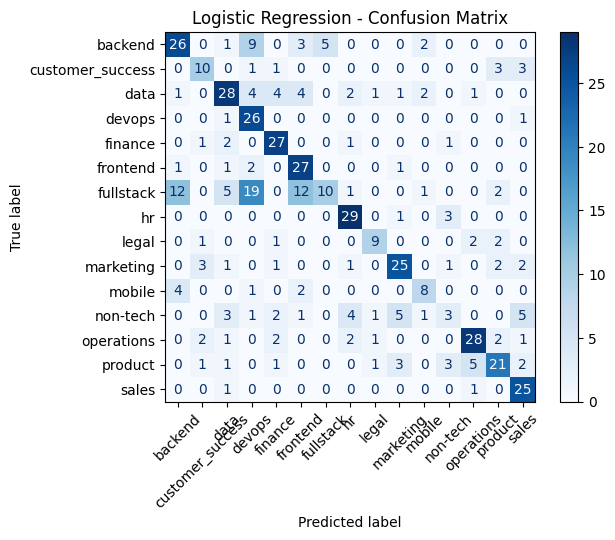

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred, labels=lr_model.classes_)
plt.figure(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=lr_model.classes_)
disp.plot(cmap='Blues',xticks_rotation=45,values_format='d')
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [19]:
from sklearn.naive_bayes import MultinomialNB
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
print("Naive Bayes training completed!")

Naive Bayes training completed!


In [20]:
y_pred_nb = nb_model.predict(X_test_tfidf)
print("Total predictions:", len(y_pred_nb))
print("\nFirst 10 predictions:")
print(y_pred_nb[:10])

Total predictions: 495

First 10 predictions:
['fullstack' 'fullstack' 'fullstack' 'fullstack' 'fullstack' 'fullstack'
 'fullstack' 'fullstack' 'fullstack' 'fullstack']


In [21]:
from sklearn.metrics import accuracy_score, classification_report
accuracy_nb = accuracy_score(y_test, y_pred_nb)
print("Naive Bayes Accuracy:", round(accuracy_nb * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

Naive Bayes Accuracy: 12.53 %

Classification Report:
                  precision    recall  f1-score   support

         backend       0.00      0.00      0.00        46
customer_success       0.00      0.00      0.00        18
            data       0.00      0.00      0.00        48
          devops       0.00      0.00      0.00        28
         finance       0.00      0.00      0.00        32
        frontend       0.00      0.00      0.00        32
       fullstack       0.13      1.00      0.22        62
              hr       0.00      0.00      0.00        33
           legal       0.00      0.00      0.00        15
       marketing       0.00      0.00      0.00        36
          mobile       0.00      0.00      0.00        15
        non-tech       0.00      0.00      0.00        26
      operations       0.00      0.00      0.00        39
         product       0.00      0.00      0.00        38
           sales       0.00      0.00      0.00        27

        accuracy

In [22]:
from collections import Counter
print("Naive Bayes Prediction Distribution:\n")
for role, count in Counter(y_pred_nb).most_common():
    print(role, ":", count)

Naive Bayes Prediction Distribution:

fullstack : 495


In [23]:
from sklearn.svm import LinearSVC
svm_model = LinearSVC(class_weight='balanced',random_state=42,max_iter=2000)
svm_model.fit(X_train_tfidf, y_train)
print("Linear SVM training completed!")

Linear SVM training completed!


In [25]:
y_pred_svm = svm_model.predict(X_test_tfidf)
print("Total predictions:", len(y_pred_svm))
print("\nFirst 10 predictions:")
print(y_pred_svm[:10])

Total predictions: 495

First 10 predictions:
['data' 'hr' 'backend' 'non-tech' 'backend' 'frontend' 'product' 'product'
 'data' 'backend']


In [26]:
## SVM confusion metrics
from sklearn.metrics import accuracy_score, classification_report
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print("Linear SVM Accuracy:", round(accuracy_svm * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

Linear SVM Accuracy: 68.48 %

Classification Report:
                  precision    recall  f1-score   support

         backend       0.64      0.76      0.69        46
customer_success       0.75      0.50      0.60        18
            data       0.66      0.69      0.67        48
          devops       0.71      0.86      0.77        28
         finance       0.68      0.88      0.77        32
        frontend       0.60      0.88      0.71        32
       fullstack       0.78      0.40      0.53        62
              hr       0.79      0.94      0.86        33
           legal       0.73      0.53      0.62        15
       marketing       0.71      0.69      0.70        36
          mobile       0.64      0.60      0.62        15
        non-tech       0.36      0.15      0.22        26
      operations       0.72      0.79      0.76        39
         product       0.70      0.68      0.69        38
           sales       0.68      0.85      0.75        27

        accuracy 

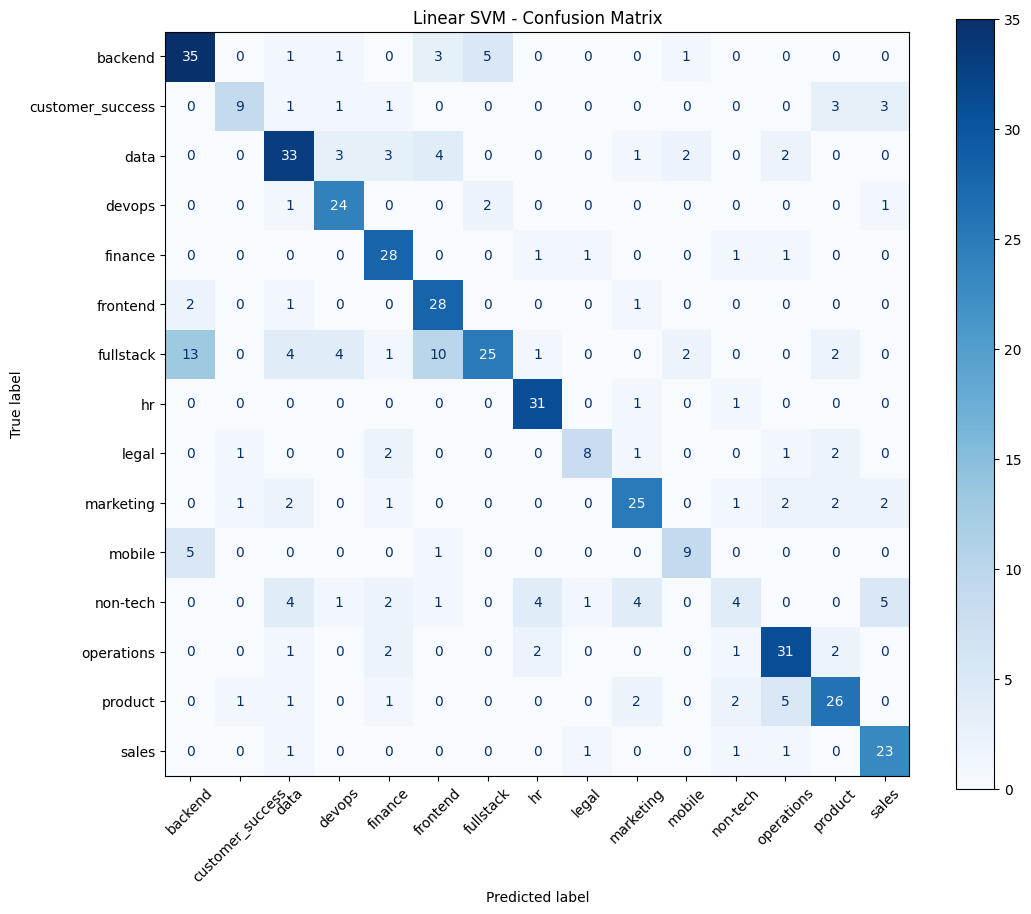

In [27]:
## SVM confusion metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_svm = confusion_matrix(y_test,y_pred_svm,labels=svm_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm,display_labels=svm_model.classes_)
fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(cmap='Blues',xticks_rotation=45,values_format='d',ax=ax)
plt.title("Linear SVM - Confusion Matrix")
plt.show()

In [28]:
import joblib
import os
os.makedirs('models', exist_ok=True)
joblib.dump(svm_model, 'models/role_family_svm.pkl')
joblib.dump(tfidf, 'models/tfidf_vectorizer.pkl')
print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [29]:
loaded_model = joblib.load('models/role_family_svm.pkl')
loaded_tfidf = joblib.load('models/tfidf_vectorizer.pkl')
print("Saved model loaded successfully!")

Saved model loaded successfully!


In [30]:
new_job_title = "Data Scientist"
new_job_description = """We are hiring a Data Scientist.The candidate should have knowledge of Python,SQL, Statistics, Machine Learning, Deep
Learning and Data Visualization.Responsibilities include data analysis,data preprocessing, feature engineering,building predictive machine learning models,model evaluation and
generating business insights."""
new_job_text = new_job_title + " " + new_job_description
new_job_tfidf = loaded_tfidf.transform([new_job_text])
predicted_role = loaded_model.predict(new_job_tfidf)
print("Job Title:", new_job_title)
print("Predicted Role Family:", predicted_role[0])

Job Title: Data Scientist
Predicted Role Family: data


In [31]:
test_jobs = [
    ("Python Backend Developer","Develop backend applications using Python, Django, Flask, APIs and SQL databases."),
    ("HR Executive","Manage recruitment, employee relations, onboarding, payroll and human resources activities."),
    ("Digital Marketing Specialist","Manage SEO, social media campaigns, Google Ads, content marketing and digital strategies."),
    ("Financial Analyst","Analyze financial data, prepare reports, budgeting, forecasting and financial planning."),
    ("Data Engineer","Build data pipelines, manage databases, ETL processes, Python, SQL and data warehouses.")]


In [32]:
for title, description in test_jobs:
    text = title + " " + description
    text_tfidf = loaded_tfidf.transform([text])
    prediction = loaded_model.predict(text_tfidf)
    print("Job:", title)
    print("Predicted Role:", prediction[0])
    print("-" * 40)

Job: Python Backend Developer
Predicted Role: backend
----------------------------------------
Job: HR Executive
Predicted Role: hr
----------------------------------------
Job: Digital Marketing Specialist
Predicted Role: marketing
----------------------------------------
Job: Financial Analyst
Predicted Role: data
----------------------------------------
Job: Data Engineer
Predicted Role: data
----------------------------------------
